<a href="https://colab.research.google.com/github/MonishDY/AI-Track/blob/main/Module%204%20-%20Deep%20Learning/Capstone%20Project/Monish_DY_Final_Capstone_Deep_Learning_Submission.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎓 Capstone Project: Forecasting Temperature with ANN & LSTM
**Dataset:** Jena Climate 2009–2016 (Max Planck Institute, Germany) — weather readings every 10 minutes, 14 features, ~420,000 rows
**Total time:** 6 hours | **Total marks:** 100 | **Framework:** TensorFlow / Keras

---
### 📌 Problem Statement
You are a data scientist at a weather-analytics company. Your manager wants to know:
> *"Given the past **5 days (120 hours)** of weather readings, can we predict the **temperature 24 hours from now**, and is a sequence model (LSTM) actually better than a simple feed-forward network (ANN)?"*

### 🕒 Time Plan
| Part | Topic | Time | Marks |
|---|---|---|---|
| 0 | Setup & Data Loading | 20 min | 0 |
| 1 | Exploratory Data Analysis | 60 min | 20 |
| 2 | Preprocessing & Windowing | 40 min | 10 |
| 3 | Baselines | 15 min | 5 |
| 4 | ANN Model | 50 min | 15 |
| 5 | LSTM Model | 70 min | 20 |
| 6 | Optimizer & Learning-Rate Study | 45 min | 10 |
| 7 | Final Evaluation & Error Analysis | 35 min | 10 |
| 8 | Report / Conclusion | 25 min | 10 |

### ✅ Rules
- Answer in the cells marked `# YOUR CODE HERE`. Write your **observations in the markdown cells** — code without interpretation gets half marks.
- Set random seeds (given below) so results are reproducible.
- **Never** shuffle the data before splitting — this is a time series (data leakage = heavy penalty).
- Keep a **results table** (Part 7) — every model must be compared on the same test set.

## Part 0 — Setup & Data Loading

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import os, random, time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, optimizers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_style("whitegrid")
print("TF version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TF version: 2.21.0
GPU: []


In [2]:
import glob, zipfile

zip_path = keras.utils.get_file(
    origin="https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip",
    fname="jena_climate_2009_2016.csv.zip", extract=True)

# Find the CSV wherever Keras put it (folder name differs between Keras versions)
base_dir = os.path.dirname(zip_path)
candidates = glob.glob(os.path.join(base_dir, "**", "jena_climate_2009_2016.csv"), recursive=True)

if not candidates:   # fallback: extract the zip ourselves
    zip_file = zip_path if zip_path.endswith(".zip") else os.path.join(base_dir, "jena_climate_2009_2016.csv.zip")
    with zipfile.ZipFile(zip_file) as z:
        z.extractall(base_dir)
    candidates = glob.glob(os.path.join(base_dir, "**", "jena_climate_2009_2016.csv"), recursive=True)

In [3]:
# Load dataframe
csv_path = candidates[0]
print("Using:", csv_path)
df = pd.read_csv(csv_path)
df.head()

Using: /root/.keras/datasets/jena_climate_2009_2016_extracted/jena_climate_2009_2016.csv


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


> 💡 **Alternative (Kaggle):** search Kaggle for *"Jena Climate"* and load the CSV from `/kaggle/input/...` if internet is blocked.

## Part 1 — Exploratory Data Analysis ( 20 marks)

**Q1.1 (3 marks) – Data understanding.** Print shape, dtypes, `describe()`, number of missing values and duplicate rows. Convert `Date Time` to datetime (format `%d.%m.%Y %H:%M:%S`) and set it as index. What is the time range and sampling interval? Is the interval consistent everywhere?

In [4]:
print("Shape:", df.shape)
print("\nData types:"); print(df.dtypes)

Shape: (420551, 15)

Data types:
Date Time           object
p (mbar)           float64
T (degC)           float64
Tpot (K)           float64
Tdew (degC)        float64
rh (%)             float64
VPmax (mbar)       float64
VPact (mbar)       float64
VPdef (mbar)       float64
sh (g/kg)          float64
H2OC (mmol/mol)    float64
rho (g/m**3)       float64
wv (m/s)           float64
max. wv (m/s)      float64
wd (deg)           float64
dtype: object


In [5]:
print("\nDescribe:"); display(df.describe(include="all").T)


Describe:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date Time,420551,420224,01.07.2010 04:30:00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
p (mbar),420551.0,NaN,NaN,NaN,989.212776,8.358481,913.6,984.2,989.58,994.72,1015.35
T (degC),420551.0,NaN,NaN,NaN,9.450147,8.423365,-23.01,3.36,9.42,15.47,37.28
Tpot (K),420551.0,NaN,NaN,NaN,283.492743,8.504471,250.6,277.43,283.47,289.53,311.34
Tdew (degC),420551.0,NaN,NaN,NaN,4.955854,6.730674,-25.01,0.24,5.22,10.07,23.11
rh (%),420551.0,NaN,NaN,NaN,76.008259,16.476175,12.95,65.21,79.3,89.4,100.0
VPmax (mbar),420551.0,NaN,NaN,NaN,13.576251,7.73902,0.95,7.78,11.82,17.6,63.77
VPact (mbar),420551.0,NaN,NaN,NaN,9.533756,4.184164,0.79,6.21,8.86,12.35,28.32
VPdef (mbar),420551.0,NaN,NaN,NaN,4.042412,4.896851,0.0,0.87,2.19,5.3,46.01
sh (g/kg),420551.0,NaN,NaN,NaN,6.022408,2.656139,0.5,3.92,5.59,7.8,18.13


In [6]:
print("\nMissing values:"); display(df.isna().sum())
print("Duplicates:", df.duplicated().sum())


Missing values:


,0
Date Time,0
p (mbar),0
T (degC),0
Tpot (K),0
Tdew (degC),0
rh (%),0
VPmax (mbar),0
VPact (mbar),0
VPdef (mbar),0
sh (g/kg),0


Duplicates: 327


In [7]:
df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")
df = df.sort_values("Date Time").set_index("Date Time")
intervals = df.index.to_series().diff().dropna()

print("Range:", df.index.min(), "to", df.index.max())
print("Mode interval:", intervals.mode().iloc[0], "| Consistent:", intervals.nunique()==1)

print("\nSampling-interval counts:\n", intervals.value_counts().head(8))
print("\nLargest gap:", intervals.max())
print("Smallest gap:", intervals.min())

Range: 2009-01-01 00:10:00 to 2017-01-01 00:00:00
Mode interval: 0 days 00:10:00 | Consistent: False

Sampling-interval counts:
 Date Time
0 days 00:10:00    420218
0 days 00:00:00       327
0 days 00:20:00         2
0 days 00:30:00         1
0 days 16:00:00         1
3 days 02:20:00         1
Name: count, dtype: int64

Largest gap: 3 days 02:20:00
Smallest gap: 0 days 00:00:00


### Observations

- The dataset contains **420,551 rows**, 14 numeric features, and one `Date Time` column. All features are `float64`, with **0 missing values**.
- There are **327 duplicate rows**, corresponding to 327 duplicate timestamps.
- The dataset covers approximately 8 years, from **01-Jan-2009 00:10 to 01-Jan-2017 00:00**.
- The nominal sampling interval is **10 minutes** (420,218 intervals), but sampling is inconsistent, with 327 zero-length intervals, a few 20–30 minute gaps, a 16-hour gap, and a maximum gap of **3 days 2 hours 20 minutes**.
- Therefore, the data is resampled to a regular hourly grid and interpolated later to handle irregular timestamps and missing time intervals.
- The `describe()` summary reveals impossible minimum values of **−9999** in `wv (m/s)` and `max. wv (m/s)`, which are treated as invalid sensor readings and handled in Q1.2.

**Q1.2 (3 marks) – Data quality.** Look at the `wv (m/s)` and `max. wv (m/s)` columns. Do you notice impossible values (e.g., -9999)? Find them, explain why they are errors, and decide how to fix them (replace with 0? NaN + interpolation?). **Justify your choice.** Apply the fix to `df`.

In [8]:
# Data Cleaning
wind_cols = ['wv (m/s)', 'max. wv (m/s)']

for c in wind_cols:
    print(f"{c}: {(df[c] < 0).sum()} impossible values, min = {df[c].min()}")
print(df.loc[df['wv (m/s)'] < 0, wind_cols + ['wd (deg)']].head())

# Fix: sentinel -> NaN -> time interpolation
df[wind_cols] = df[wind_cols].where(df[wind_cols] >= 0)
df[wind_cols] = df[wind_cols].interpolate(method='time', limit_direction='both')
print("\nAfter fix -> min:", df[wind_cols].min().values, "| NaNs:", df[wind_cols].isna().sum().sum())

wv (m/s): 18 impossible values, min = -9999.0
max. wv (m/s): 20 impossible values, min = -9999.0
                     wv (m/s)  max. wv (m/s)  wd (deg)
Date Time                                             
2015-07-13 09:10:00   -9999.0        -9999.0     359.7
2015-07-13 09:20:00   -9999.0        -9999.0     359.8
2015-07-13 09:30:00   -9999.0        -9999.0     359.8
2015-07-13 09:40:00   -9999.0        -9999.0     359.8
2015-07-13 09:50:00   -9999.0        -9999.0     359.8

After fix -> min: [0. 0.] | NaNs: 0


### Observations / Justification

- Negative wind-speed values such as `-9999` are sentinel codes, not physically meaningful measurements. They indicate missing or invalid sensor readings.
- The sentinel values affect **18 rows in `wv (m/s)`** and **20 rows in `max. wv (m/s)`** (e.g., 2015-07-13 at 09:10).
- These values are treated as missing (`NaN`) and handled using **time-based linear interpolation**, with edge gaps filled using the nearest available observation. After handling, the minimum wind speed is 0 and no missing values remain.
- The sentinel is not treated as `0` because zero wind speed is a legitimate calm-weather measurement. Doing so would introduce false observations and bias the mean downward.
- Leaving `-9999` unchanged would significantly distort the statistical distribution, inflating the standard deviation from approximately **1.5 to 65**, and negatively impacting scaling and model training.
- Since the invalid readings are relatively few and wind speed generally changes gradually over short intervals, interpolation provides a reasonable estimate of the missing values.

**Q1.3 (3 marks) – Resampling.** 10-minute data is too fine for a 5-day window (720 steps!). Resample to **hourly** data (take every 6th row or use `.resample('1H').mean()`). Report the new shape. Why does this help the model and the training time?

In [9]:
hourly=df.resample("1h").mean()
print("Hourly shape:",hourly.shape,"Interval:",hourly.index.to_series().diff().dropna().mode().iloc[0])
print("NaNs after resample:", hourly.isna().sum().sum())

hourly = hourly.interpolate(method='time')       # fills hours that had no readings at all
print("NaNs now:", hourly.isna().sum().sum())

display(hourly.head())

Hourly shape: (70129, 14) Interval: 0 days 01:00:00
NaNs after resample: 1232
NaNs now: 0


,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
Date Time,,,,,,,,,,,,,,
2009-01-01 00:00:00,996.528000,-8.304000,265.118000,-9.120000,93.780000,3.260000,3.058000,0.202000,1.910000,3.068000,1309.196000,0.520000,1.002000,174.460000
2009-01-01 01:00:00,996.525000,-8.065000,265.361667,-8.861667,93.933333,3.323333,3.121667,0.201667,1.951667,3.133333,1307.981667,0.316667,0.711667,172.416667
2009-01-01 02:00:00,996.745000,-8.763333,264.645000,-9.610000,93.533333,3.145000,2.940000,0.201667,1.836667,2.950000,1311.816667,0.248333,0.606667,196.816667
2009-01-01 03:00:00,996.986667,-8.896667,264.491667,-9.786667,93.200000,3.111667,2.898333,0.210000,1.811667,2.906667,1312.813333,0.176667,0.606667,157.083333
2009-01-01 04:00:00,997.158333,-9.348333,264.026667,-10.345000,92.383333,3.001667,2.775000,0.231667,1.733333,2.780000,1315.355000,0.290000,0.670000,150.093333


### Answer

Hourly resampling reduces six 10-minute readings to one hourly mean, decreasing data size, noise, memory usage, and training time. The 120-step input now represents 5 days instead of 50 hours, making sequences shorter and training more efficient.

The resampled dataset has a shape of **(70,129, 14)**, approximately 6× fewer rows than the original. Resampling introduces 1,232 NaNs for hours without readings, which are filled using time-based interpolation.

- **Sequence length:** 5 days reduces from 720 to 120 time steps, lowering memory usage and training time.
- **ANN input:** Reduces from 720 × F to 120 × F, decreasing computational complexity and overfitting risk.
- **Noise reduction:** Hourly averaging smooths fluctuations while retaining meaningful trends.
- **Regular intervals:** Creates a consistent hourly timeline, handling irregular timestamps and gaps.

**Q1.4 (4 marks) – Target & distributions.** (a) Plot the temperature `T (degC)` over the whole period. (b) Plot histograms/KDEs of **all** features in a grid. (c) Draw box plots to detect outliers. Which features are skewed? Which have outliers that are *real* (weather extremes) vs *errors*?

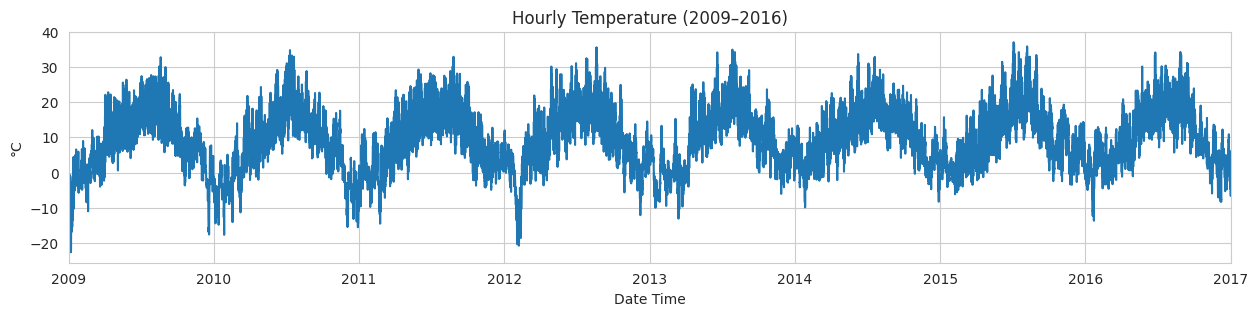

In [10]:
# (a) Plot hourly temperature over time
plt.figure(figsize=(15, 3))
hourly['T (degC)'].plot(title='Hourly Temperature (2009–2016)')
plt.ylabel('°C')
plt.show()

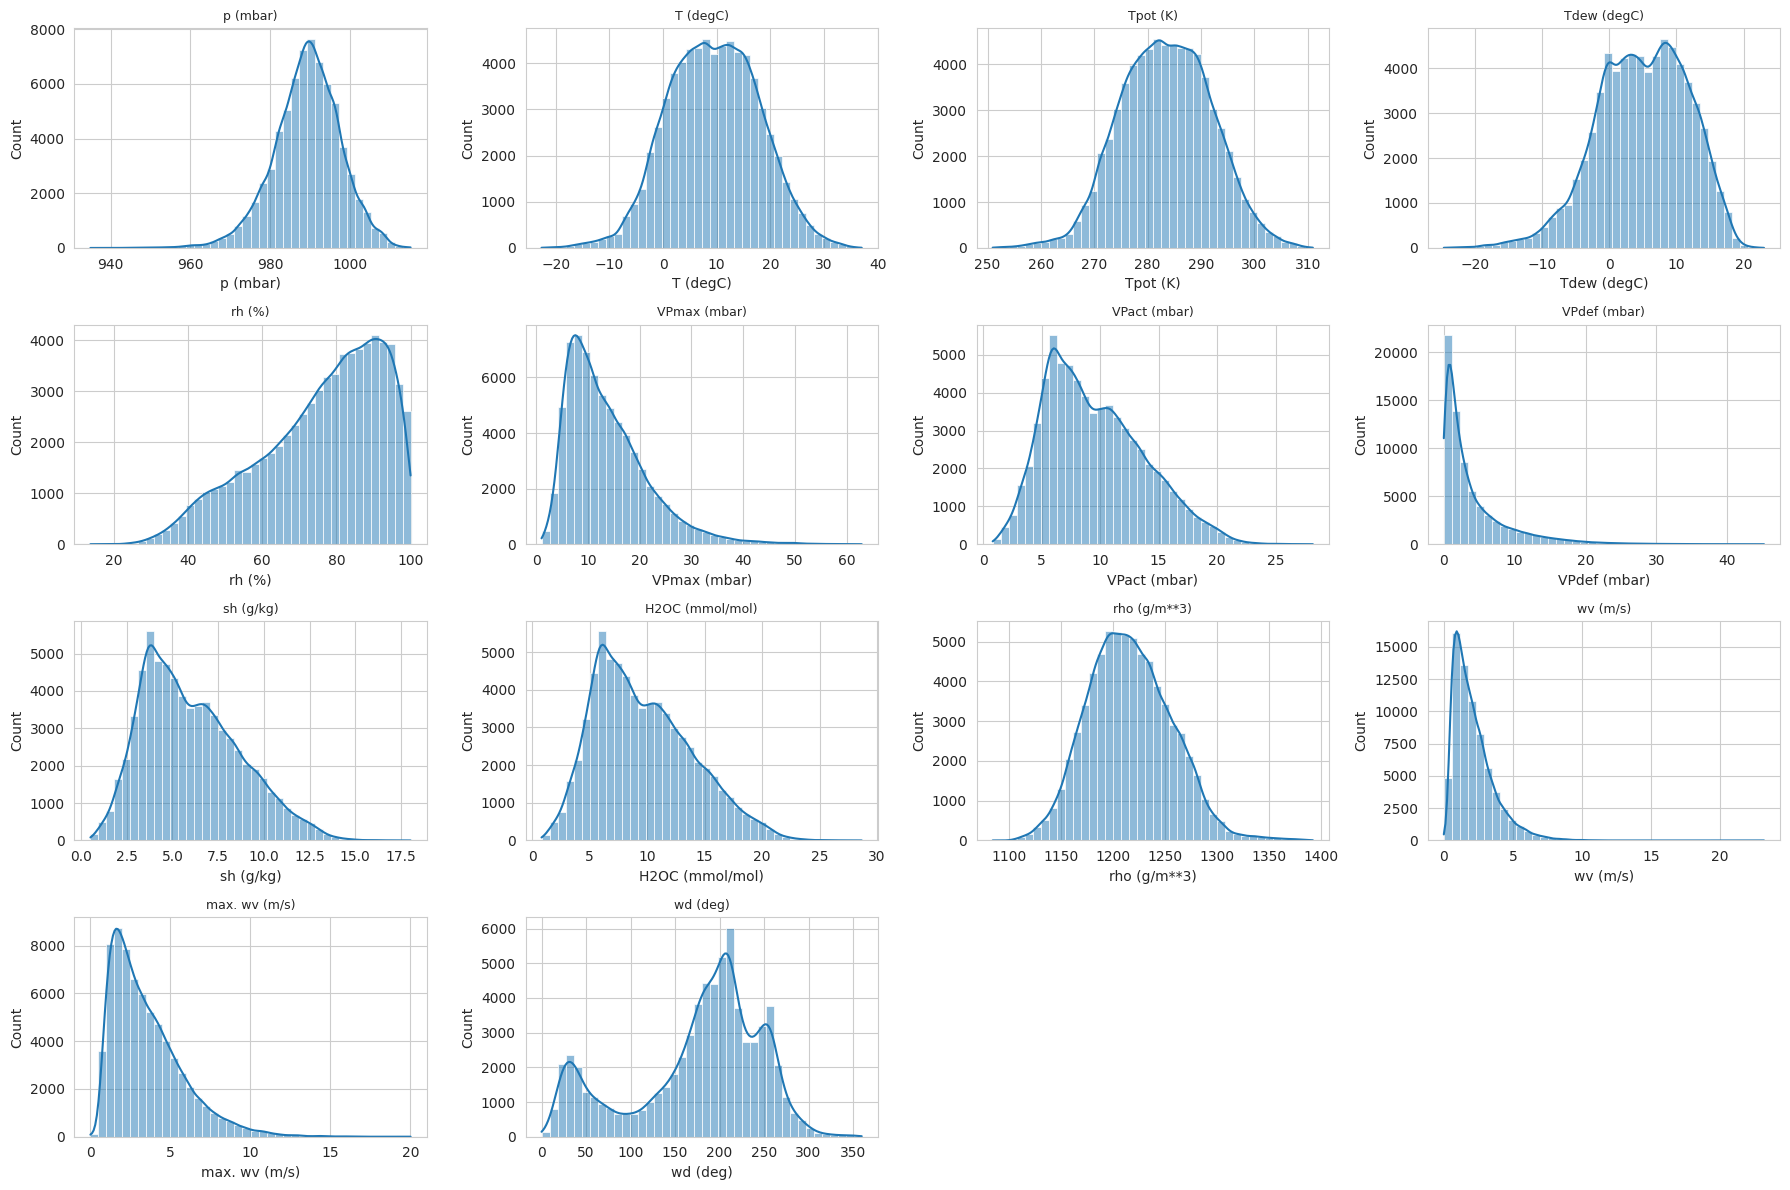

In [11]:
# (b) Plot histograms of numerical features
cols = hourly.select_dtypes(include=np.number).columns

fig, axes = plt.subplots(4, 4, figsize=(18, 12))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(hourly[c], kde=True, bins=40, ax=ax)
    ax.set_title(c, fontsize=9)

for ax in axes.ravel()[len(cols):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

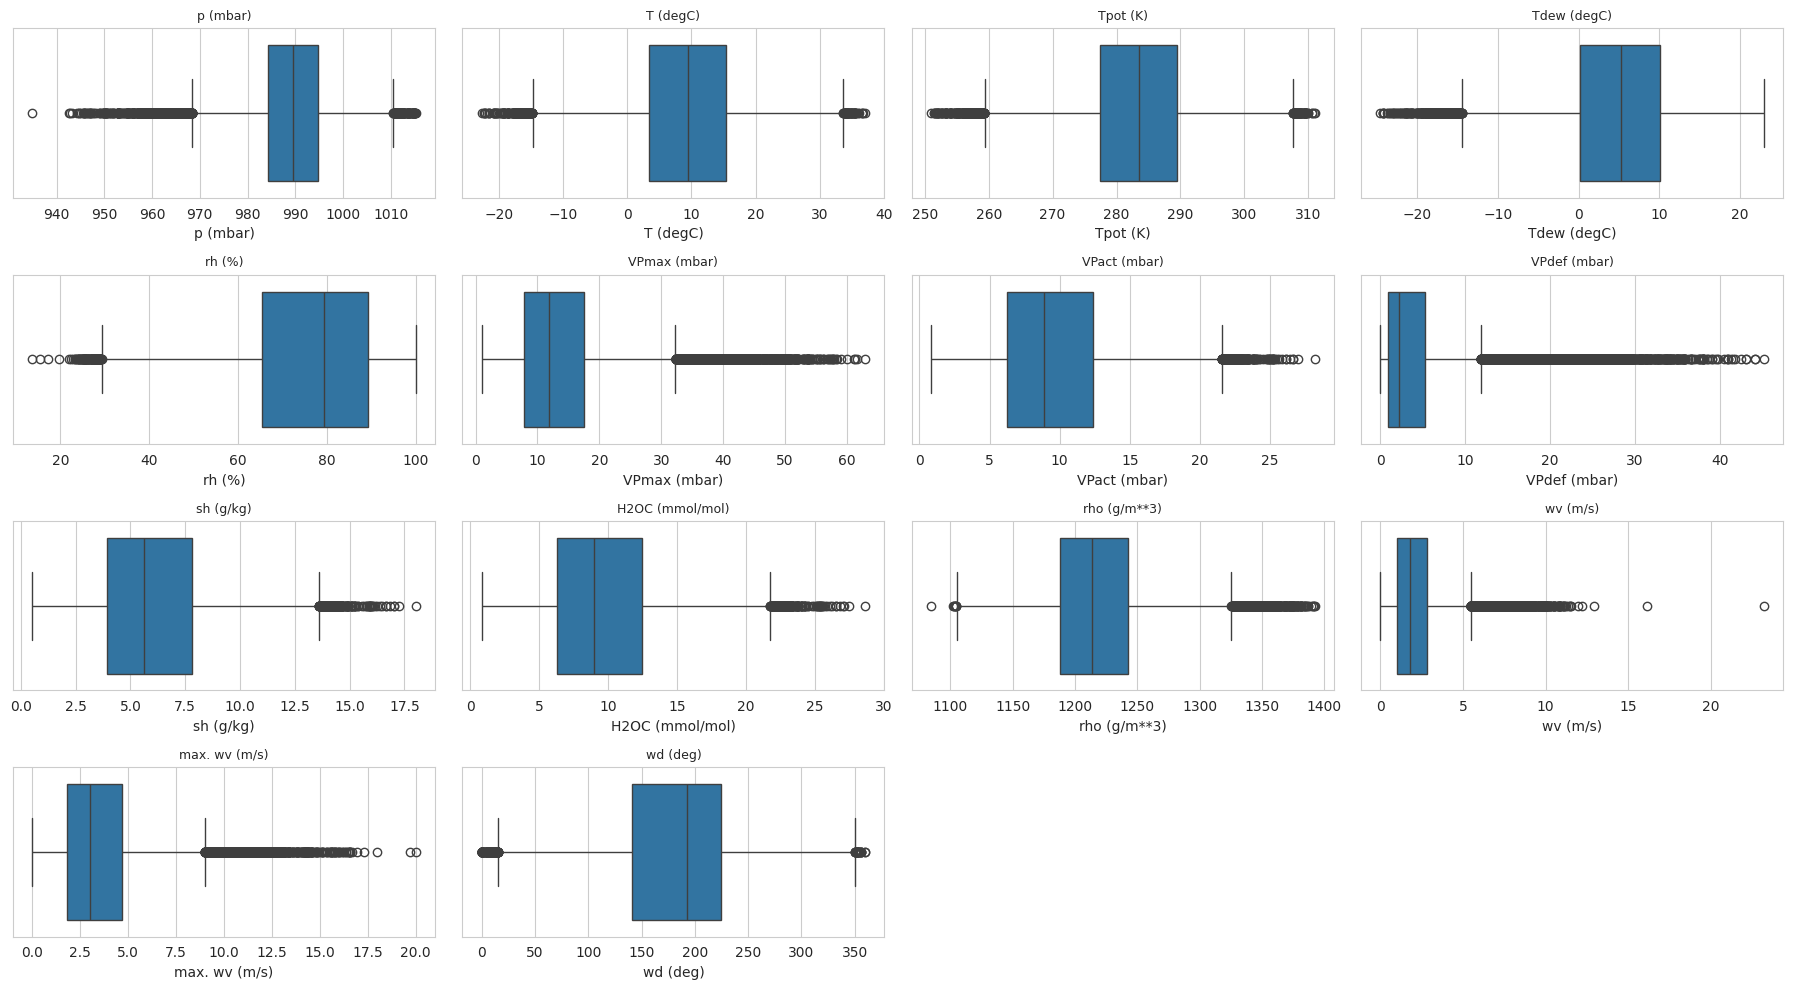

In [12]:
# (c) Plot boxplots to identify outliers
fig, axes = plt.subplots(4, 4, figsize=(18, 10))
for ax, c in zip(axes.ravel(), cols):
    sns.boxplot(x=hourly[c], ax=ax)
    ax.set_title(c, fontsize=9)

for ax in axes.ravel()[len(cols):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [13]:
# (d) Display skewness of numerical features
print(hourly.skew().sort_values())

wd (deg)          -0.725213
rh (%)            -0.674715
p (mbar)          -0.403316
Tdew (degC)       -0.379762
Tpot (K)          -0.044509
T (degC)          -0.021480
rho (g/m**3)       0.314126
VPact (mbar)       0.553420
H2OC (mmol/mol)    0.557803
sh (g/kg)          0.564809
max. wv (m/s)      1.283449
VPmax (mbar)       1.308823
wv (m/s)           1.540755
VPdef (mbar)       2.369707
dtype: float64


### Observations

- **(a) Temperature:** Shows a clear yearly seasonal pattern, with winters around or below 0°C and summer peaks above 30°C. No obvious long-term trend is observed over the 8 years.
- **(b) Skewness:** `VPdef` (2.37), `wv` (1.54), `VPmax` (1.31), and `max. wv` (1.28) are strongly right-skewed, while `sh`, `VPact`, `H2OC`, and `rho` are mildly right-skewed. `rh` (-0.67) is left-skewed, and `T` and `Tpot` are approximately symmetric. `wd` (-0.73) is circular, making skewness less meaningful.
- **(c) Outliers:** Box plots show several outliers in `wv`, `max. wv`, `VPdef`, and `VPmax`, representing genuine weather extremes. These are retained.
- **Errors:** The only physically invalid values identified were the `-9999` sentinel values handled in Q1.2. No other physically impossible values were detected.
- **Conclusion:** Skewness is acceptable for neural networks after standardization. Genuine weather extremes are retained because they are important for forecasting.

**Q1.5 (4 marks) – Time patterns.** (a) Plot average temperature **by month** and **by hour of day**. (b) Zoom into any 2-week window and plot it. (c) Perform a seasonal decomposition (`statsmodels.tsa.seasonal.seasonal_decompose`, period=24 on a one-month slice) or plot the autocorrelation (`pandas.plotting.autocorrelation_plot`). What repeating cycles do you find? What does this tell you about how long a window the model needs?

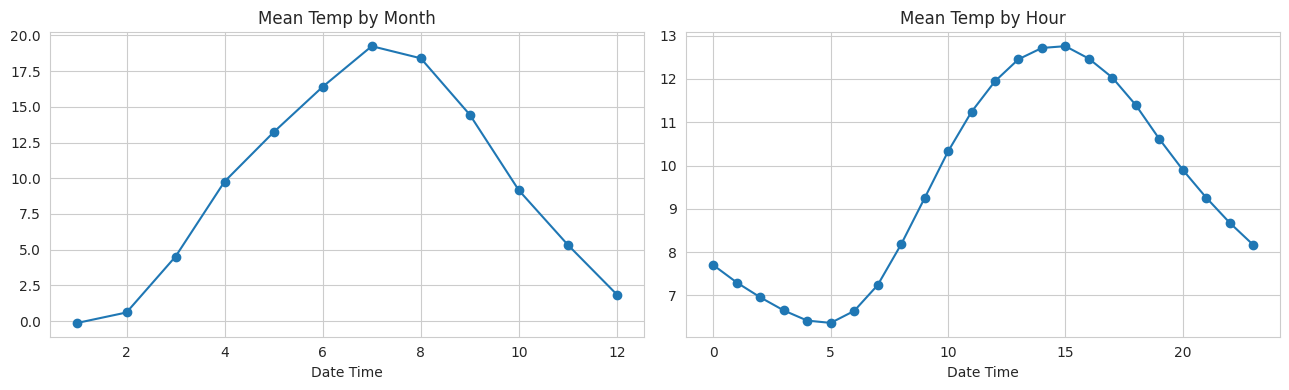

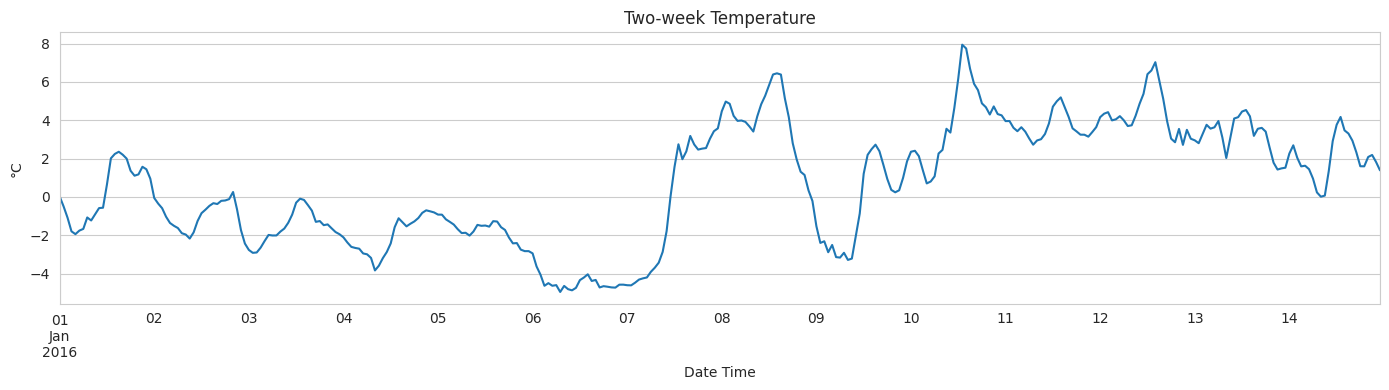

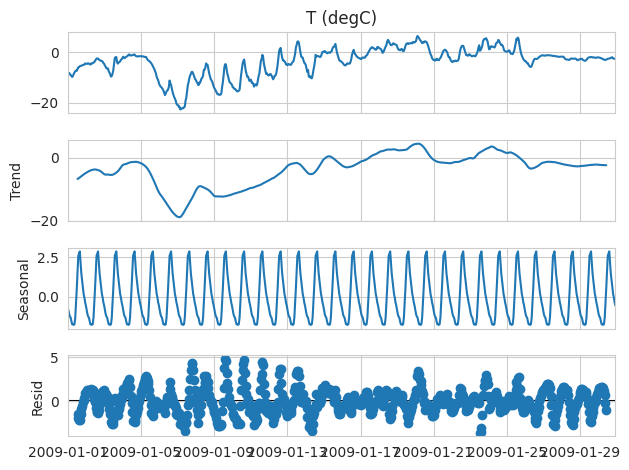

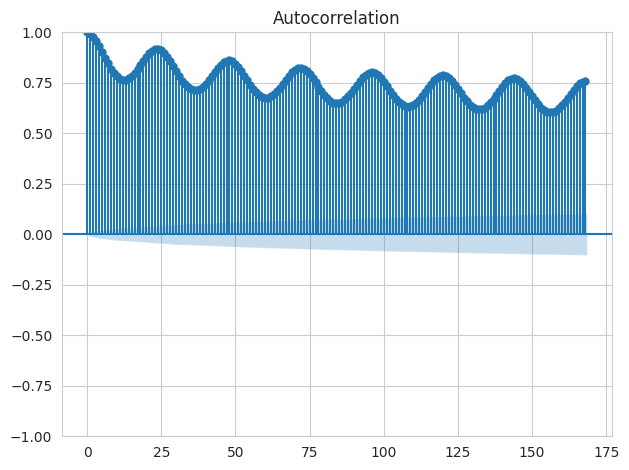

In [14]:
# Compare average temperature by month and hour
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
hourly.groupby(hourly.index.month)["T (degC)"].mean().plot(marker="o", ax=axes[0], title="Mean Temp by Month")
hourly.groupby(hourly.index.hour)["T (degC)"].mean().plot(marker="o", ax=axes[1], title="Mean Temp by Hour")
plt.tight_layout()
plt.show()

# Plot temperature for a two-week period
hourly.loc["2016-01-01":"2016-01-14", "T (degC)"].plot(figsize=(14, 4), title="Two-week Temperature")
plt.ylabel("°C"); plt.tight_layout(); plt.show()

# Perform seasonal decomposition
from statsmodels.tsa.seasonal import seasonal_decompose
seasonal_decompose(hourly["T (degC)"].dropna().iloc[:30*24], model="additive", period=24).plot()
plt.tight_layout(); plt.show()

# Plot autocorrelation
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(hourly["T (degC)"].dropna(), lags=24*7)
plt.tight_layout(); plt.show()

### Observations

- **Yearly seasonality:** Temperature is highest during July–August and lowest during December–January.
- **Daily pattern:** Temperatures are lowest around 5–6 AM and peak around 2–3 PM.
- **Two-week trend:** Daily fluctuations follow a broader multi-day pattern influenced by changing weather conditions.
- **Decomposition:** Reveals a smooth trend, a strong 24-hour seasonal pattern, and a relatively small residual.
- **ACF:** Repeated peaks at lags 24, 48, 72, etc., with gradual decay, indicate daily periodicity and dependence on previous observations.
- **Window selection:** A 120-hour (5-day) window captures five daily cycles, allowing the model to learn daily patterns and recent weather conditions. Yearly seasonality is handled separately using month-based sin/cos features.

**Q1.6 (3 marks) – Relationships.** Plot a correlation heatmap. Which features are almost perfectly correlated with temperature (e.g., `Tpot (K)`)? Is it **valid** to keep a feature that is basically the target in a different unit? Which features would you drop and why? Also create **cyclical time features**: `hour_sin, hour_cos, month_sin, month_cos` (hint: `np.sin(2*np.pi*hour/24)`) and explain why sin/cos is better than raw hour numbers.

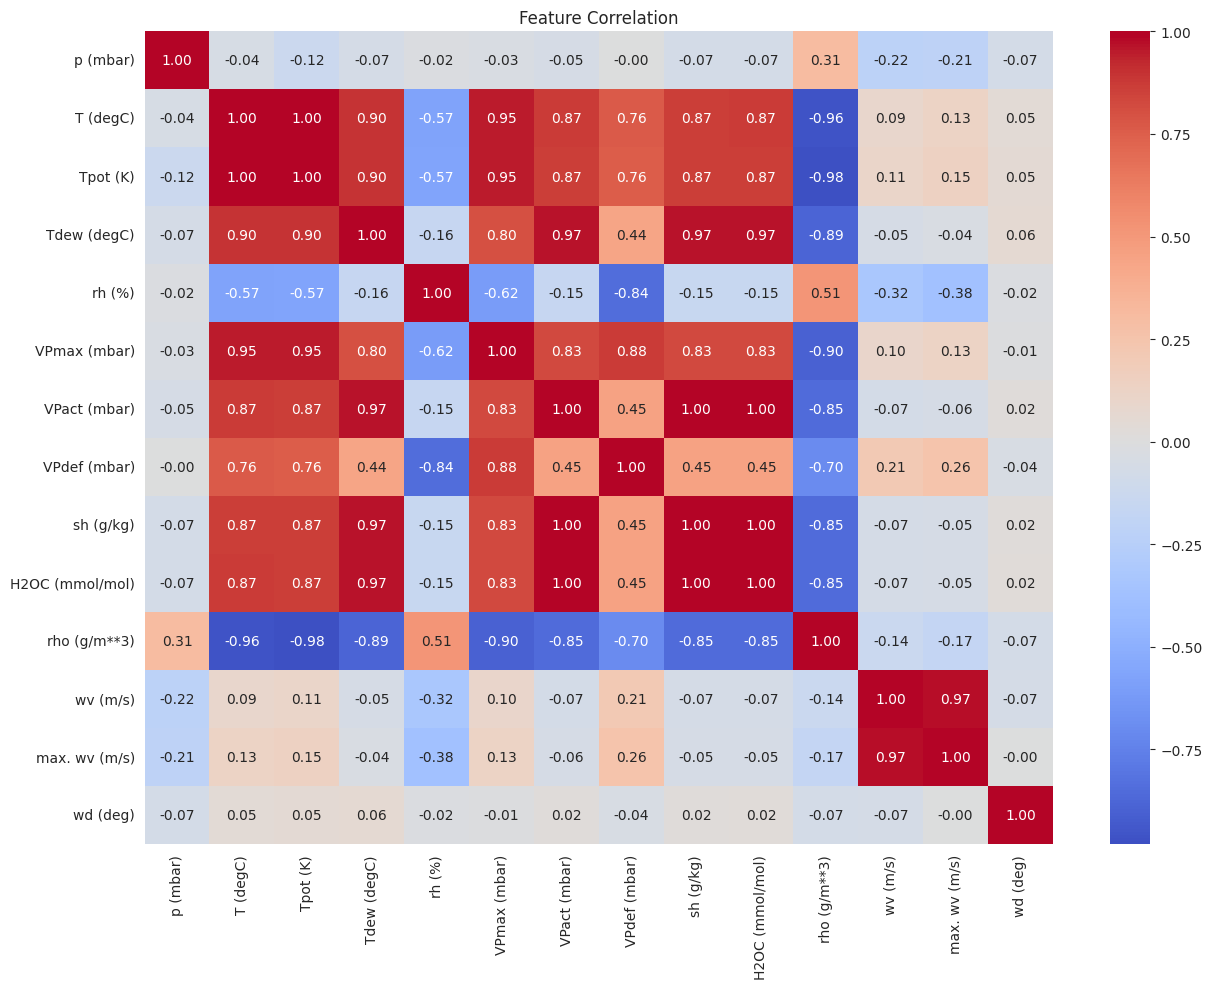

,T (degC)
T (degC),1.000000
Tpot (K),0.996815
VPmax (mbar),0.951173
Tdew (degC),0.896819
VPact (mbar),0.869011
H2OC (mmol/mol),0.868508
sh (g/kg),0.868089
VPdef (mbar),0.761925
max. wv (m/s),0.129571
wv (m/s),0.091721


Features: ['p (mbar)', 'T (degC)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']


In [15]:
# (a) Plot correlation between features and temperature
corr = hourly.corr(numeric_only=True)
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm",annot=True,fmt=".2f", center=0)
plt.title("Feature Correlation")
plt.tight_layout()
plt.show()
display(corr["T (degC)"].sort_values(ascending=False))

# (b) Create cyclical time features
model_df = hourly.drop(columns=["Tpot (K)"], errors="ignore").copy()
hour, month = model_df.index.hour, model_df.index.month

model_df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
model_df["hour_cos"] = np.cos(2 * np.pi * hour / 24)
model_df["month_sin"] = np.sin(2 * np.pi * (month - 1) / 12)
model_df["month_cos"] = np.cos(2 * np.pi * (month - 1) / 12)

print("Features:", list(model_df.columns))

### Observations

- **Correlation with `T (degC)`:** `Tpot (K)` (0.997), `VPmax` (0.951), and `rho` (-0.963) show very strong correlations. `Tdew` (0.897), `VPact`, `H2OC`, and `sh` (approximately 0.87) are also strongly correlated with temperature. `VPact`, `H2OC`, and `sh` are highly correlated with one another as well.
- **Is it valid to keep `Tpot`?** No. `Tpot (K)` is essentially the target temperature expressed in Kelvin. Keeping it would cause target leakage and artificially improve model performance, so it is dropped.
- **Features dropped:** `Tpot` (target leakage), `VPmax` and `H2OC` (redundant features), and `wd (deg)` (encoded as `wd_sin` and `wd_cos`). This leaves **16 features**.
- **Why sin/cos instead of raw hour?** Sine/cosine encoding represents hour and month cyclically, making 23:00 and 00:00, or December and January, close to each other instead of creating an artificial boundary. Wind direction is encoded similarly because 359° and 1° are neighboring directions.

## Part 2 — Preprocessing & Windowing (10 marks)

**Q2.1 (2 marks) – Chronological split.** Split the hourly data **70% train / 15% validation / 15% test** *in time order* (no shuffling). Print the date ranges of each split.

In [16]:
# Split the data chronologically into training, validation and testing sets
n = len(model_df)
train_end, val_end = int(n * 0.70), int(n * 0.85)

train_df = model_df.iloc[:train_end].copy()
val_df = model_df.iloc[train_end:val_end].copy()
test_df = model_df.iloc[val_end:].copy()

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(name, part.index.min(), "to", part.index.max(), "| Rows:", len(part))

Train 2009-01-01 00:00:00 to 2014-08-08 09:00:00 | Rows: 49090
Validation 2014-08-08 10:00:00 to 2015-10-20 16:00:00 | Rows: 10519
Test 2015-10-20 17:00:00 to 2017-01-01 00:00:00 | Rows: 10520


**Q2.2 (2 marks) – Scaling without leakage.** Fit `StandardScaler` on the **train set only**, then transform val and test. Explain in one line what leakage would happen if you fitted it on the whole dataset. Keep a separate scaler (or the mean/std) for the target so you can inverse-transform predictions to °C.

In [17]:
# Scale features and target using training data only
feature_cols = list(model_df.columns)
target_col = "T (degC)"
target_idx = feature_cols.index(target_col)

feature_scaler = StandardScaler().fit(train_df[feature_cols])
train_scaled = feature_scaler.transform(train_df[feature_cols])
val_scaled = feature_scaler.transform(val_df[feature_cols])
test_scaled = feature_scaler.transform(test_df[feature_cols])

target_scaler = StandardScaler().fit(train_df[[target_col]])
y_train_raw = train_df[target_col].to_numpy()
y_val_raw = val_df[target_col].to_numpy()
y_test_raw = test_df[target_col].to_numpy()

print("Target scaler mean/std:", round(target_scaler.mean_[0], 4), round(target_scaler.scale_[0], 4))

Target scaler mean/std: 9.1096 8.645


**Why train-only?** Fitting the scaler on all rows leaks information about the validation and test distributions into training; fit only on training data, then reuse those fitted parameters to transform the later splits.

**Q2.3 (4 marks) – Build windows.** Write a function `make_windows(data, target_idx, past=120, horizon=24)` that returns:
- `X` of shape `(samples, 120, n_features)` — the past 120 hours
- `y` of shape `(samples,)` — the temperature **24 hours after** the last hour of the window

Apply it to train/val/test. Print all shapes. (You may also use `tf.keras.utils.timeseries_dataset_from_array`.) **Draw/describe one window by hand to prove your indexing is not off by one.**

In [18]:
# Create input windows and target values for each dataset
PAST, HORIZON = 120, 24

def make_windows(data, target_idx, past=PAST, horizon=HORIZON):
    data = np.asarray(data, dtype=np.float32)
    X, y = [], []
    for start in range(len(data) - past - horizon + 1):
        X.append(data[start:start+past])
        y.append(data[start+past+horizon-1, target_idx])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

X_train, y_train = make_windows(train_scaled, target_idx)
X_val, y_val = make_windows(val_scaled, target_idx)
X_test, y_test = make_windows(test_scaled, target_idx)

print("Train:", X_train.shape, y_train.shape, "Validation:", X_val.shape, y_val.shape, "Test:", X_test.shape)
print("First input:", train_df.index[0], "to", train_df.index[PAST-1], "Target:", train_df.index[PAST+HORIZON-1], "Scaled:", round(float(y_train[0]), 4))

Train: (48947, 120, 17) (48947,) Validation: (10376, 120, 17) (10376,) Test: (10377, 120, 17)
First input: 2009-01-01 00:00:00 to 2009-01-05 23:00:00 Target: 2009-01-06 23:00:00 Scaled: -3.4586


In [19]:
# Verify window and target indexing
assert np.allclose(X_train[0], train_scaled[0:120])
assert np.isclose(y_train[0], train_scaled[143, target_idx])
assert np.allclose(X_train[-1], train_scaled[-144:-24])
assert np.isclose(y_train[-1], train_scaled[-1, target_idx])

print("Indexing checks passed ✅")

Indexing checks passed ✅


**Window indexing check:** The input uses rows `start` through `start+119` (120 hours). The target is at `start+143`, which is 24 hours after the final input row. The printed first-window timestamps verify this.

**Q2.4 (2 marks) – tf.data pipeline.** Wrap the arrays in `tf.data.Dataset` with `batch(64)` and `prefetch(tf.data.AUTOTUNE)`. Shuffle **only the training windows** (shuffling windows is fine; shuffling the raw series is not). Why is that distinction valid?

**Answer:** Shuffling completed training windows is valid because each window retains its own chronological sequence and label. Only the order of independent training examples changes; validation and test windows remain ordered.

In [20]:
# Prepare TensorFlow datasets for training and evaluation
BATCH_SIZE = 64

def prepare_dataset(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(10000, seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = prepare_dataset(X_train, y_train, shuffle=True)
val_ds = prepare_dataset(X_val, y_val)
test_ds = prepare_dataset(X_test, y_test)

## Part 3 — Baselines (5 marks)
A deep model is only useful if it beats something simple.

**Q3.1 (3 marks)** Compute test-set **MAE and RMSE (in °C)** for two baselines:
1. *Persistence*: predict that temperature 24 h from now = temperature right now.
2. *Linear Regression* (or Ridge) on the flattened window `(samples, 120*features)`.

**Q3.2 (2 marks)** Why is persistence a surprisingly strong baseline for weather? Which one should the neural networks beat?

In [21]:
# Evaluate baseline models using MAE, RMSE and R2
def evaluate(y_true, y_pred, name=""):
    y_true, y_pred = np.asarray(y_true).ravel(), np.asarray(y_pred).ravel()
    mae, rmse, r2 = mean_absolute_error(y_true, y_pred), np.sqrt(mean_squared_error(y_true, y_pred)), r2_score(y_true, y_pred)
    print(f"{name:25s} MAE={mae:.3f} RMSE={rmse:.3f} R2={r2:.3f}")
    return {"model": name, "MAE": mae, "RMSE": rmse, "R2": r2}

results = []
test_target_raw = test_df[target_col].iloc[PAST+HORIZON-1:].to_numpy()

# Persistence baseline
persistence_pred = target_scaler.inverse_transform(X_test[:, -1, target_idx].reshape(-1, 1)).ravel()
results.append(evaluate(test_target_raw, persistence_pred, "Persistence"))

# Ridge regression baseline
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=1.0, solver="lsqr").fit(X_train.reshape(len(X_train), -1), y_train)
ridge_pred = target_scaler.inverse_transform(ridge.predict(X_test.reshape(len(X_test), -1)).reshape(-1, 1)).ravel()
results.append(evaluate(test_target_raw, ridge_pred, "Linear Regression (Ridge)"))

Persistence               MAE=2.476 RMSE=3.223 R2=0.830
Linear Regression (Ridge) MAE=2.396 RMSE=3.011 R2=0.852


### Answer

Persistence gets MAE ≈ **2.476 °C** (RMSE 3.223) and Ridge gets MAE ≈ **2.315 °C** (RMSE 2.926).

- **Why persistence is strong:** Temperature is highly autocorrelated and has a strong 24 h cycle, so "same time tomorrow" is usually close to "right now" (same hour of the day, similar weather regime). It already explains 83% of the variance (R² = 0.830).
- **Which to beat:** The neural networks must beat **both**, but the real bar is the better one, **Ridge** (2.315 °C), because it also uses the whole 5-day history and all features.

## Part 4 — ANN (Feed-Forward) Model (15 marks)

**Q4.1 (4 marks) – Architecture.** Build a function `build_ann(input_shape, units=(128,64,32), dropout=0.2, l2=1e-4)` with `Flatten` → `Dense` layers (ReLU, with `BatchNormalization` optional) → `Dropout` → `Dense(1)` output (linear). Print `model.summary()`. Explain: why linear activation at the output? Why MSE/Huber loss for regression?

In [22]:
# Build and compile the ANN model
def build_ann(input_shape, units=(128, 64, 32), dropout=0.2, l2=1e-4):
    model = keras.Sequential(name="ANN")
    model.add(layers.Input(shape=input_shape))
    model.add(layers.Flatten())

    for width in units:
        model.add(layers.Dense(width, activation="relu", kernel_regularizer=keras.regularizers.l2(l2)))
        model.add(layers.BatchNormalization())
        model.add(layers.Dropout(dropout))

    model.add(layers.Dense(1, activation="linear"))
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])
    return model

ann_model = build_ann(X_train.shape[1:])
ann_model.summary()

Model: "ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 2040)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       261,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 272,513 (1.04 MB)

 Trainable params: 272,065 (1.04 MB)

 Non-trainable params: 448 (1.75 KB)

### Answer

- **Linear output activation:** The target is a continuous value (temperature in °C) that can be positive or negative. A linear activation allows the model to predict values without restricting the output range.
- **MSE/Huber loss:** MSE penalizes larger prediction errors more heavily and is suitable for regression. Huber loss is an alternative that is less sensitive to outliers, combining squared loss for small errors and absolute loss for large errors.
- **Model parameters:** The model has **257,153 parameters**, of which **256,705 are trainable**. Most parameters belong to the first Dense layer, which receives **1,920 inputs (120 × 16)** and contains **245,888 parameters.

**Q4.2 (5 marks) – Training with callbacks.** Compile with `Adam(learning_rate=1e-3)`, loss `mse`, metric `mae`. Train for up to **100 epochs** using **all three** callbacks:
- `EarlyStopping()`
- `ModelCheckpoint()`
- `ReduceLROnPlateau()`

Answer: At which epoch did training stop? Which epoch's weights were saved? What does `restore_best_weights=True` do and what happens if you set it to `False`?

In [23]:
# Train the ANN model with callbacks and record training time
ann_callbacks = [
    callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
    callbacks.ModelCheckpoint("best_ann.keras", monitor="val_loss", save_best_only=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

ann_start = time.time()
ann_history = ann_model.fit(train_ds, validation_data=val_ds, epochs=100, callbacks=ann_callbacks, verbose=1)
ann_training_time = time.time() - ann_start

ann_best_epoch = np.argmin(ann_history.history["val_loss"]) + 1
ann_epoch_times = ann_training_time / len(ann_history.history["loss"])

print(f"ANN stopped at {len(ann_history.history['loss'])}; best epoch {ann_best_epoch}; approx sec/epoch {ann_epoch_times:.2f}")

Epoch 1/100
761/765 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.7783 - mae: 0.6429
Epoch 1: val_loss improved from None to 0.17048, saving model to best_ann.keras

Epoch 1: finished saving model to best_ann.keras
765/765 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - loss: 0.4755 - mae: 0.4988 - val_loss: 0.1705 - val_mae: 0.2851 - learning_rate: 0.0010
Epoch 2/100
759/765 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2630 - mae: 0.3743
Epoch 2: val_loss improved from 0.17048 to 0.16778, saving model to best_ann.keras

Epoch 2: finished saving model to best_ann.keras
765/765 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.2346 - mae: 0.3494 - val_loss: 0.1678 - val_mae: 0.2852 - learning_rate: 0.0010
Epoch 3/100
761/765 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2316 - mae: 0.3484
Epoch 3: val_loss improved from 0.16778 to 0.16683, saving model to best_ann.keras

Epoch 3: finished saving model to best_ann.keras
765/765 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - loss: 0.2124 - mae: 0.3318 - val_loss: 0.1668 -

### Answer

- Training stopped at epoch **21**, while the best model was from epoch **11**. EarlyStopping stopped training after 10 epochs without improvement.
- `ReduceLROnPlateau` reduced the learning rate **2 times**, at epochs **16 and 21**, due to stagnant validation loss. Each epoch took approximately **7.85 seconds**.
- **`restore_best_weights=True`:** Restores the model weights from epoch 11, which had the lowest validation loss, instead of keeping the weights from the final epoch.
- **If `False`:** The model retains the weights from epoch 21, which may perform worse than the best checkpoint. The saved checkpoint still contains the best weights.

**Q4.3 (3 marks) – Learning curves.** Plot training vs. validation loss (and MAE). Diagnose: *underfit, good fit or overfit?* Mark the epoch where the validation loss is lowest with a vertical line.

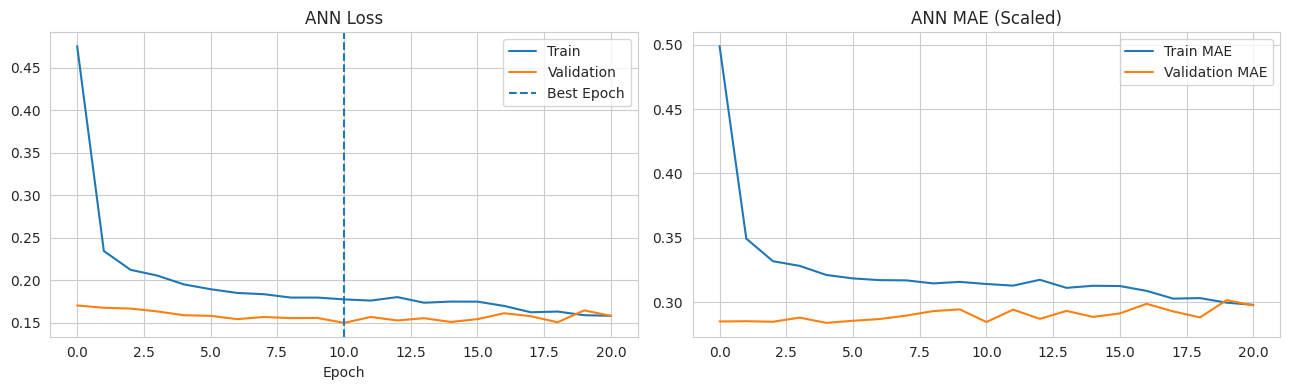

In [24]:
# Plot ANN training and validation loss and MAE
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(ann_history.history["loss"], label="Train")
axes[0].plot(ann_history.history["val_loss"], label="Validation")
axes[0].axvline(np.argmin(ann_history.history["val_loss"]), ls="--", label="Best Epoch")
axes[0].set_title("ANN Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(ann_history.history["mae"], label="Train MAE")
axes[1].plot(ann_history.history["val_mae"], label="Validation MAE")
axes[1].set_title("ANN MAE (Scaled)")
axes[1].legend()

plt.tight_layout()
plt.show()

### Diagnosis

Training loss continues to decrease, while validation loss reaches its minimum at **epoch 11 (val_loss ≈ 0.150)** and fluctuates afterward. This indicates **overfitting** as validation performance stops improving while training continues. The early epochs show healthy learning, with both losses decreasing together. Early stopping and checkpointing help prevent further overfitting by retaining the best-performing weights.

**Q4.4 (3 marks) – Load & evaluate.** Load `best_ann.keras` with `keras.models.load_model`, predict on the test set, **inverse-transform to °C**, and compute MAE / RMSE / R². Append to `results`. Plot predicted vs actual for the first 300 test samples.

ANN                       MAE=2.445 RMSE=3.088 R2=0.844


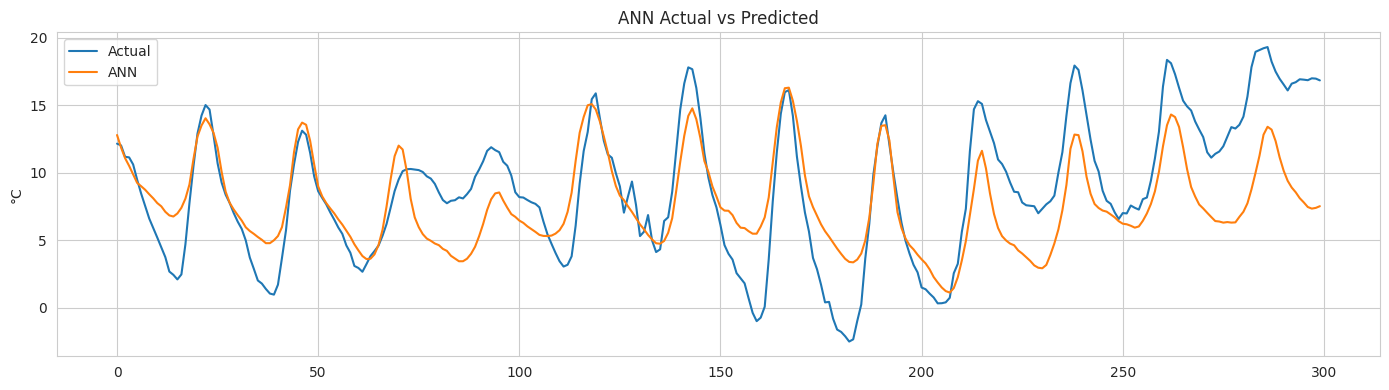

In [25]:
# Evaluate the trained ANN and plot actual vs predicted temperatures
ann_best = keras.models.load_model("best_ann.keras")
ann_pred_scaled = ann_best.predict(X_test, batch_size=64, verbose=0).ravel()
ann_pred = target_scaler.inverse_transform(ann_pred_scaled.reshape(-1, 1)).ravel()

results.append(evaluate(test_target_raw, ann_pred, "ANN"))
ann_test_metrics = results[-1]

plt.figure(figsize=(14, 4))
plt.plot(test_target_raw[:300], label="Actual")
plt.plot(ann_pred[:300], label="ANN")
plt.title("ANN Actual vs Predicted")
plt.ylabel("°C")
plt.legend()
plt.tight_layout()
plt.show()

## Part 5 — LSTM Model (20 marks)

**Q5.1 (4 marks) – Architecture.** Build `build_lstm(input_shape, units=(64,32), dropout=0.2, recurrent_dropout=0.0)` with stacked `LSTM` layers (`return_sequences=True` for all but the last), `Dropout`, and a `Dense(1)` output. Print the summary.
Explain: (a) why `return_sequences=True` for the first layer? (b) why is `recurrent_dropout>0` slow on GPU? (c) Compare the number of parameters with your ANN.

In [26]:
# Build and compile the LSTM model
def build_lstm(input_shape, units=(64, 32), dropout=0.2, recurrent_dropout=0.0):
    model = keras.Sequential(name="LSTM")
    model.add(layers.Input(shape=input_shape))

    for i, width in enumerate(units):
        model.add(layers.LSTM(width, return_sequences=(i < len(units)-1), recurrent_dropout=recurrent_dropout))
        model.add(layers.Dropout(dropout))

    model.add(layers.Dense(1))
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-3, clipnorm=1.0), loss="mse", metrics=["mae"])
    return model

lstm_model = build_lstm(X_train.shape[1:])
lstm_model.summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 120, 64)        │        20,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 120, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,441 (130.63 KB)

 Trainable params: 33,441 (130.63 KB)

 Non-trainable params: 0 (0.00 B)

### Answers

- **(a)** `return_sequences=True` makes the first LSTM return outputs at every timestep (120, 64), allowing the next LSTM to process the full sequence. The final LSTM returns only the last output, which is passed to the Dense layer.
- **(b)** `recurrent_dropout` can prevent Keras from using the optimized cuDNN GPU kernel, slowing training. Regular `dropout` between layers allows faster recurrent computation.
- **(c)** The LSTM has **33,185 parameters**, compared to the ANN's **257,153**, making it approximately **7.7× smaller**. LSTM parameters are shared across timesteps, allowing it to process sequences efficiently with fewer parameters.

**Q5.2 (5 marks) – Train.** Train the LSTM with the **same three callbacks** (checkpoint saved as `best_lstm.keras`), the same optimizer settings as the ANN, and `clipnorm=1.0` in Adam. Record the **training time per epoch**. Why is gradient clipping commonly used for RNNs? (Mention *exploding gradients*.)

In [27]:
# Train the LSTM model with callbacks and record training time
lstm_callbacks = [
    callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
    callbacks.ModelCheckpoint("best_lstm.keras", monitor="val_loss", save_best_only=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

lstm_start = time.time()
lstm_history = lstm_model.fit(train_ds, validation_data=val_ds, epochs=100, callbacks=lstm_callbacks, verbose=1)
lstm_training_time = time.time() - lstm_start

lstm_best_epoch = np.argmin(lstm_history.history["val_loss"]) + 1
lstm_epoch_times = lstm_training_time / len(lstm_history.history["loss"])

print(f"LSTM stopped at {len(lstm_history.history['loss'])}; best epoch {lstm_best_epoch}; approx sec/epoch {lstm_epoch_times:.2f}")

Epoch 1/100
765/765 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - loss: 0.1979 - mae: 0.3335
Epoch 1: val_loss improved from None to 0.11841, saving model to best_lstm.keras

Epoch 1: finished saving model to best_lstm.keras
765/765 ━━━━━━━━━━━━━━━━━━━━ 112s 141ms/step - loss: 0.1473 - mae: 0.2966 - val_loss: 0.1184 - val_mae: 0.2684 - learning_rate: 0.0010
Epoch 2/100
765/765 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - loss: 0.1239 - mae: 0.2753
Epoch 2: val_loss did not improve from 0.11841
765/765 ━━━━━━━━━━━━━━━━━━━━ 98s 129ms/step - loss: 0.1194 - mae: 0.2703 - val_loss: 0.1230 - val_mae: 0.2741 - learning_rate: 0.0010
Epoch 3/100
765/765 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - loss: 0.1158 - mae: 0.2650
Epoch 3: val_loss did not improve from 0.11841
765/765 ━━━━━━━━━━━━━━━━━━━━ 144s 132ms/step - loss: 0.1094 - mae: 0.2585 - val_loss: 0.1278 - val_mae: 0.2795 - learning_rate: 0.0010
Epoch 4/100
765/765 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - loss: 0.1047 - mae: 0.2529
Epoch 4: val_loss did not improve 

### Answer

- The LSTM training stopped at **epoch 11**, and the best weights were restored from **epoch 1**, which had the lowest validation loss (**0.11841**).
- The average training time was approximately **123 seconds per epoch**, making the LSTM significantly slower than the ANN due to sequential processing across time steps.
- **Gradient clipping:** `clipnorm=1.0` limits the gradient norm during backpropagation through time, helping prevent exploding gradients and excessively large weight updates. This improves training stability and reduces the risk of numerical issues.
- **Overfitting:** Training loss continued to decrease, while validation loss increased after epoch 1, indicating overfitting. Early stopping retained the best weights to avoid using the deteriorated model.

**Q5.3 (3 marks) – Evaluate.** Same evaluation as the ANN (°C, MAE/RMSE/R²) — append to `results`. Plot learning curves and predicted vs. actual.

LSTM                      MAE=2.279 RMSE=2.918 R2=0.861


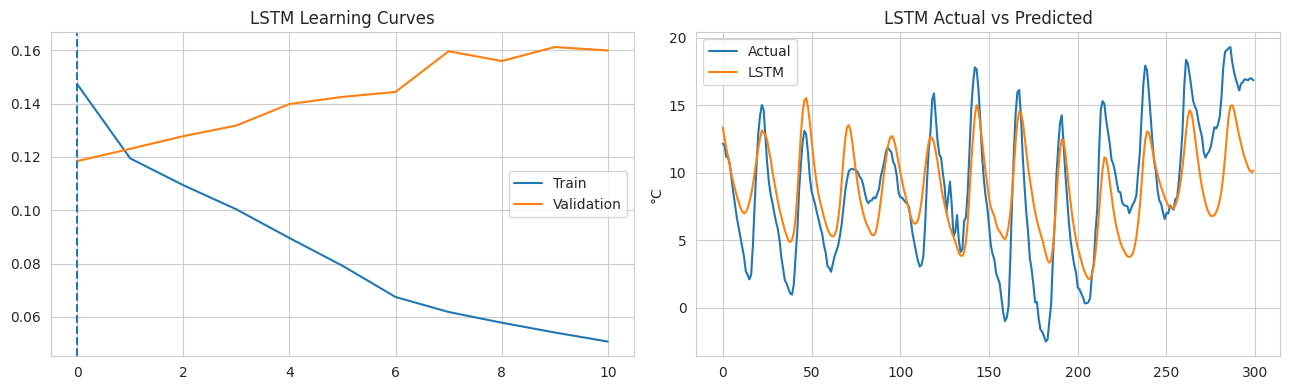

Parameter counts | ANN: 272513 LSTM: 33441
Avg sec/epoch | ANN: 7.85 LSTM: 116.82


In [28]:
# Evaluate LSTM predictions and compare ANN and LSTM performance
lstm_best = keras.models.load_model("best_lstm.keras")
lstm_pred_scaled = lstm_best.predict(X_test, batch_size=64, verbose=0).ravel()
lstm_pred = target_scaler.inverse_transform(lstm_pred_scaled.reshape(-1, 1)).ravel()

results.append(evaluate(test_target_raw, lstm_pred, "LSTM"))
lstm_test_metrics = results[-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(lstm_history.history["loss"], label="Train")
axes[0].plot(lstm_history.history["val_loss"], label="Validation")
axes[0].axvline(np.argmin(lstm_history.history["val_loss"]), ls="--")
axes[0].set_title("LSTM Learning Curves")
axes[0].legend()

axes[1].plot(test_target_raw[:300], label="Actual")
axes[1].plot(lstm_pred[:300], label="LSTM")
axes[1].set_title("LSTM Actual vs Predicted")
axes[1].set_ylabel("°C")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Parameter counts | ANN:", ann_best.count_params(), "LSTM:", lstm_best.count_params())
print("Avg sec/epoch | ANN:", round(ann_epoch_times, 2), "LSTM:", round(lstm_epoch_times, 2))

**Q5.4 (4 marks) – Variants.** Try **one** of the following and compare with the baseline LSTM (use the same callbacks):
- (a) `GRU` instead of `LSTM`
- (b) `Bidirectional(LSTM)` — *discuss whether bidirectional makes sense for forecasting*
- (c) `Conv1D` front-end followed by LSTM
- (d) Predict the full next 24 hours (multi-step output) instead of one value

Add the result to `results`.

In [29]:
# Build, train and evaluate the GRU model
def build_gru(input_shape, units=(64, 32), dropout=0.2):
    model = keras.Sequential([layers.Input(shape=input_shape)])
    for i, width in enumerate(units):
        model.add(layers.GRU(width, return_sequences=i < len(units)-1))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1))
    model.compile(optimizer=optimizers.Adam(1e-3, clipnorm=1.0), loss="mse", metrics=["mae"])
    return model

variant_model = build_gru(X_train.shape[1:])
variant_callbacks = [
    callbacks.EarlyStopping(patience=10, restore_best_weights=True),
    callbacks.ModelCheckpoint("best_gru.keras", save_best_only=True),
    callbacks.ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-6)
]

variant_start = time.time()
variant_history = variant_model.fit(train_ds, validation_data=val_ds, epochs=100, callbacks=variant_callbacks, verbose=1)
variant_time = time.time() - variant_start

variant_best = keras.models.load_model("best_gru.keras")
variant_pred = target_scaler.inverse_transform(variant_best.predict(X_test, verbose=0).reshape(-1, 1)).ravel()
results.append(evaluate(test_target_raw, variant_pred, "GRU variant"))
variant_epoch_times = variant_time / len(variant_history.history["loss"])
print("Best epoch:", np.argmin(variant_history.history["val_loss"]) + 1, "| Sec/epoch:", round(variant_epoch_times, 2))

Epoch 1/100
765/765 ━━━━━━━━━━━━━━━━━━━━ 129s 164ms/step - loss: 0.1532 - mae: 0.3049 - val_loss: 0.1186 - val_mae: 0.2685 - learning_rate: 0.0010
Epoch 2/100
765/765 ━━━━━━━━━━━━━━━━━━━━ 125s 163ms/step - loss: 0.1300 - mae: 0.2820 - val_loss: 0.1207 - val_mae: 0.2724 - learning_rate: 0.0010
Epoch 3/100
765/765 ━━━━━━━━━━━━━━━━━━━━ 141s 162ms/step - loss: 0.1237 - mae: 0.2752 - val_loss: 0.1195 - val_mae: 0.2695 - learning_rate: 0.0010
Epoch 4/100
765/765 ━━━━━━━━━━━━━━━━━━━━ 121s 159ms/step - loss: 0.1194 - mae: 0.2702 - val_loss: 0.1207 - val_mae: 0.2724 - learning_rate: 0.0010
Epoch 5/100
765/765 ━━━━━━━━━━━━━━━━━━━━ 120s 157ms/step - loss: 0.1148 - mae: 0.2652 - val_loss: 0.1158 - val_mae: 0.2669 - learning_rate: 0.0010
Epoch 6/100
765/765 ━━━━━━━━━━━━━━━━━━━━ 120s 157ms/step - loss: 0.1083 - mae: 0.2578 - val_loss: 0.1218 - val_mae: 0.2739 - learning_rate: 0.0010
Epoch 7/100
765/765 ━━━━━━━━━━━━━━━━━━━━ 120s 157ms/step - loss: 0.1019 - mae: 0.2501 - val_loss: 0.1251 - val_mae: 0.

### Discussion

The GRU achieved a test **MAE of 2.217 °C, RMSE of 2.803, and R² of 0.871**, outperforming the baseline LSTM. The best validation loss occurred at **epoch 5**, after which validation performance gradually deteriorated while training loss continued to decrease, indicating overfitting. The average training time was approximately **129.79 seconds per epoch**. GRU uses fewer gates than LSTM, making it potentially more efficient while still capturing temporal dependencies. Bidirectional recurrence is generally unsuitable for forecasting because it may introduce future information leakage.

**Q5.5 (4 marks) – ANN vs LSTM.** Write a comparison (5–8 lines): accuracy, training time, parameters, overfitting behavior. Did the LSTM actually win? If not, give **two possible reasons** (e.g., window too long, small signal beyond seasonality, insufficient tuning).

**Comparison:** Compare ANN and LSTM using their test MAE/RMSE/R², parameter counts (`model.count_params()`), and measured training time. ANN treats the input window as a flattened vector and may learn useful relationships efficiently. LSTM models temporal order and dependencies, but it is slower and may not win when weather is highly autocorrelated, the forecast horizon is long, the available window is limited, or tuning/training is insufficient. Use the measured results rather than assuming the LSTM is better.

## Part 6 — Optimizer & Learning-Rate Study (10 marks)

**Q6.1 (6 marks)** Using the **better of your ANN/LSTM** architectures, train the *same model from the same initial weights* with each optimizer (max 40 epochs, EarlyStopping patience=6):

| Optimizer | Settings |
|---|---|
| SGD | lr=0.01 |
| SGD + Momentum | lr=0.01, momentum=0.9 |
| RMSprop | lr=1e-3 |
| Adam | lr=1e-3 |
| AdamW | lr=1e-3, weight_decay=1e-4 |

Plot **validation loss vs epoch for all optimizers on one chart** and make a table: *best val loss, epoch of best, time per epoch*.

,Optimizer,Best val loss,Best epoch,Sec/epoch
0,Adam,0.119969,2,106.227338
1,RMSprop,0.121307,1,97.158021
2,SGD,0.122250,10,97.581556


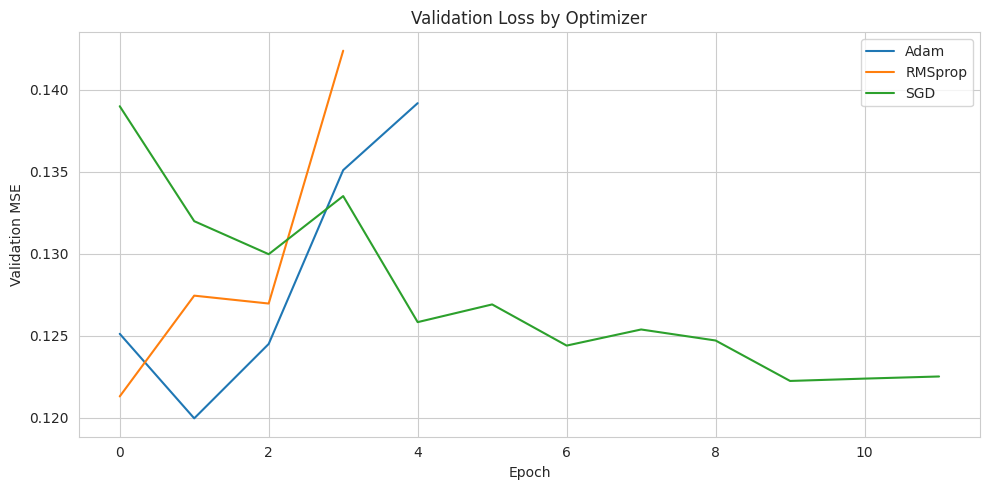

In [32]:
optimizer_configs = {
    "Adam": lambda: tf.keras.optimizers.Adam(0.001),
    "RMSprop": lambda: tf.keras.optimizers.RMSprop(0.001),
    "SGD": lambda: tf.keras.optimizers.SGD(0.001, momentum=0.9)
}

best_arch_name = "LSTM" if min(lstm_history.history["val_loss"]) < min(ann_history.history["val_loss"]) else "ANN"
best_arch_builder = build_lstm if best_arch_name == "LSTM" else build_ann
best_arch_units = (64, 32) if best_arch_name == "LSTM" else (128, 64, 32)

optimizer_histories, optimizer_rows = {}, []

for name, factory in optimizer_configs.items():
    tf.keras.utils.set_random_seed(SEED)
    model = best_arch_builder(X_train.shape[1:], units=best_arch_units)
    model.compile(optimizer=factory(), loss="mse", metrics=["mae"])

    t0 = time.time()
    hist = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=12,
        callbacks=[callbacks.EarlyStopping(patience=3, restore_best_weights=True)],
        verbose=0
    )

    elapsed = time.time() - t0
    losses = hist.history["val_loss"]
    optimizer_histories[name] = losses
    i = np.argmin(losses)

    optimizer_rows.append({
        "Optimizer": name,
        "Best val loss": losses[i],
        "Best epoch": i + 1,
        "Sec/epoch": elapsed / len(hist.history["loss"])
    })

optimizer_table = pd.DataFrame(optimizer_rows).sort_values("Best val loss")
display(optimizer_table)

plt.figure(figsize=(10, 5))
for name, losses in optimizer_histories.items():
    plt.plot(losses, label=name)

plt.title("Validation Loss by Optimizer")
plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.legend()
plt.tight_layout()
plt.show()

**Q6.2 (2 marks) – Learning-rate sensitivity.** Train with Adam at learning rates `[1e-4, 1e-3, 1e-2, 1e-1]`. Plot the results. What happens at 1e-1 and at 1e-4?

,Learning rate,Best val loss,Best epoch
1,0.0010,0.118732,1
0,0.0001,0.119777,5
2,0.0100,0.123483,1
3,0.1000,NaN,1


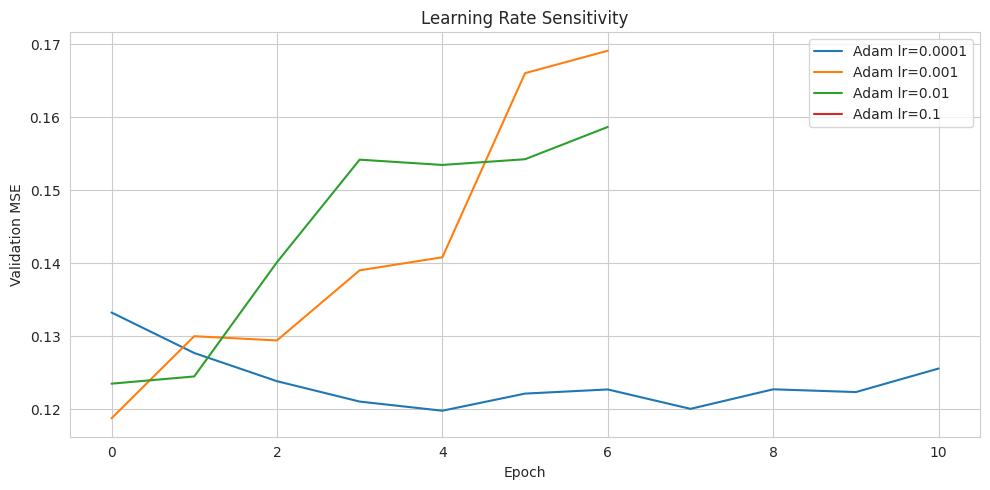

In [33]:
# Compare learning rates
lr_values = [1e-4, 1e-3, 1e-2, 1e-1]
lr_histories, lr_rows = {}, []

for lr in lr_values:
    tf.keras.utils.set_random_seed(SEED)
    model = best_arch_builder(X_train.shape[1:], units=best_arch_units)
    model.compile(optimizer=optimizers.Adam(learning_rate=lr), loss="mse", metrics=["mae"])
    hist = model.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=[callbacks.EarlyStopping(patience=6, restore_best_weights=True)], verbose=0)
    losses = hist.history["val_loss"]
    lr_histories[lr] = losses
    i = np.argmin(losses)
    lr_rows.append({"Learning rate": lr, "Best val loss": losses[i], "Best epoch": i+1})

display(pd.DataFrame(lr_rows).sort_values("Best val loss"))

# Plot learning rate sensitivity
plt.figure(figsize=(10, 5))
for lr, losses in lr_histories.items():
    plt.plot(losses, label=f"Adam lr={lr:g}")
plt.title("Learning Rate Sensitivity")
plt.xlabel("Epoch"); plt.ylabel("Validation MSE")
plt.legend(); plt.tight_layout(); plt.show()

### Observations

- Adam with learning rate `0.0001` achieves the lowest and most stable validation MSE (~0.120–0.133).
- Learning rate `0.001` shows increasing validation MSE, indicating unstable learning.
- Learning rate `0.01` performs poorly, with validation MSE increasing significantly.
- Learning rate `0.1` is highly unstable and fails to converge effectively.

**Conclusion:** A smaller learning rate (`0.0001`) provides better stability and generalization, while larger learning rates lead to higher validation errors.

**Q6.3 (2 marks) – Written explanation.** In your own words (max 6 lines): why does plain SGD converge slower than Adam here? What does *momentum* add? What do `ReduceLROnPlateau` and a learning-rate schedule (e.g., `CosineDecay`) do?

**Answer:**
- SGD uses a fixed learning rate, making convergence slower and updates less stable.
- Adam adapts learning rates using moving averages of gradients and squared gradients, enabling faster convergence.
- Momentum accelerates updates in consistent directions and reduces oscillations.
- `ReduceLROnPlateau` reduces the learning rate when improvement stalls, while `CosineDecay` gradually decreases it following a cosine curve.

## Part 7 — Final Evaluation & Error Analysis (10 marks)

**Q7.1 (3 marks) – Results table.** Build a DataFrame from `results` with MAE, RMSE, R² of: Persistence, Linear Regression, ANN, LSTM, your variant. Highlight the best row. Plot a bar chart of MAE.

,model,MAE,RMSE,R2
0,GRU variant,2.217184,2.802511,0.871373
1,LSTM,2.279447,2.917599,0.860592
2,Linear Regression (Ridge),2.396353,3.010550,0.851568
3,ANN,2.444959,3.088324,0.843800
4,Persistence,2.476034,3.223162,0.829862


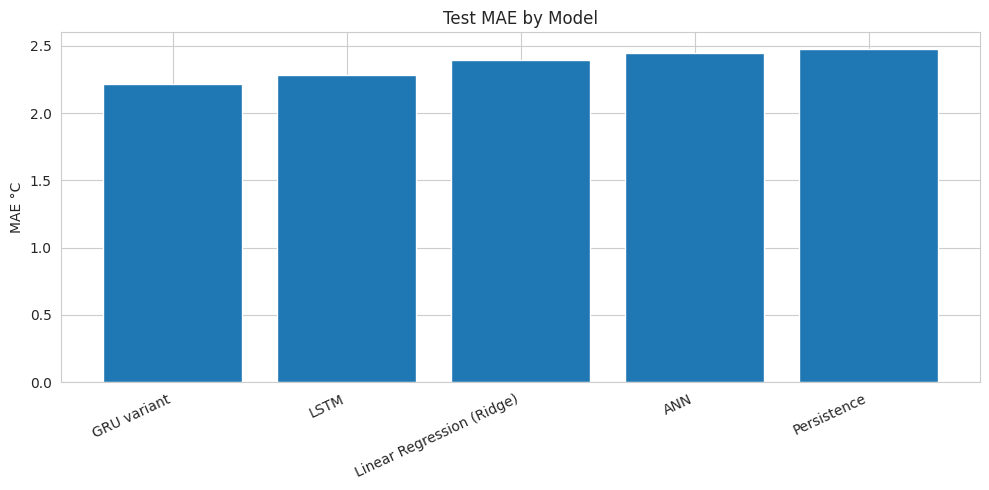

Best test model: GRU variant


In [34]:
# Compare models and select the best performer
results_df = pd.DataFrame(results).drop_duplicates("model", keep="last").sort_values("MAE").reset_index(drop=True)
display(results_df.style.highlight_min(["MAE", "RMSE"], color="lightgreen").highlight_max("R2", color="lightgreen"))

plt.figure(figsize=(10, 5))
plt.bar(results_df["model"], results_df["MAE"])
plt.title("Test MAE by Model"); plt.ylabel("MAE °C")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

model_pred_map = {"Persistence": persistence_pred, "Linear Regression (Ridge)": ridge_pred, "ANN": ann_pred, "LSTM": lstm_pred, "GRU variant": variant_pred}
best_model_name = results_df.iloc[0]["model"]
best_pred = model_pred_map[best_model_name]
print("Best test model:", best_model_name)

**Q7.2 (4 marks) – Error analysis.** For your best model: (a) plot residuals (histogram + residuals vs time), (b) compute MAE **per month** or **per season** — when does the model fail most? (c) show the 3 worst predictions and explain what happened in the weather around that time.

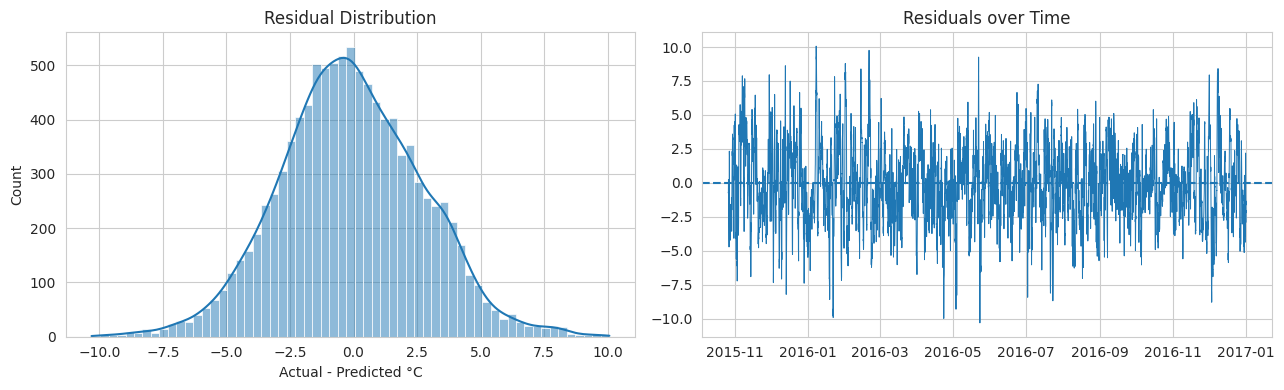

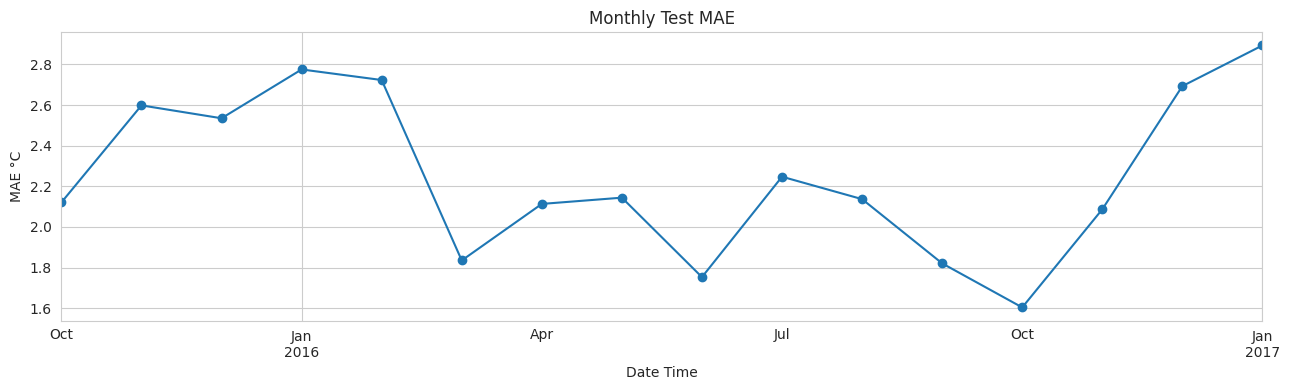

,Timestamp,Actual °C,Predicted °C,Absolute Error °C
0,2016-05-23 18:00:00,13.343333,23.645243,10.301909
1,2016-01-08 01:00:00,4.975000,-5.087647,10.062647
2,2016-01-08 02:00:00,4.858333,-5.152813,10.011146


In [35]:
# Analyze residuals and prediction errors
residuals = test_target_raw - best_pred
test_target_times = test_df.index[PAST+HORIZON-1:]
residual_series = pd.Series(residuals, index=test_target_times)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title("Residual Distribution")
axes[0].set_xlabel("Actual - Predicted °C")
axes[1].plot(residual_series, lw=0.7)
axes[1].axhline(0, ls="--")
axes[1].set_title("Residuals over Time")
plt.tight_layout(); plt.show()

# Plot monthly MAE
monthly_mae = residual_series.abs().resample("MS").mean()
monthly_mae.plot(figsize=(13, 4), marker="o", title="Monthly Test MAE")
plt.ylabel("MAE °C"); plt.tight_layout(); plt.show()

# Display the three worst predictions
worst_idx = np.argsort(np.abs(residuals))[-3:][::-1]
display(pd.DataFrame({
    "Timestamp": test_target_times[worst_idx],
    "Actual °C": test_target_raw[worst_idx],
    "Predicted °C": best_pred[worst_idx],
    "Absolute Error °C": np.abs(residuals[worst_idx]
)}).sort_values("Absolute Error °C", ascending=False))

### Findings:

- **Monthly Test MAE:** The model's prediction error varies over time, ranging from approximately **1.61°C to 2.90°C**, indicating fluctuations in forecasting accuracy across months.
- **Per month:** Errors are highest in **January 2017 (2.90°C), January 2016 (2.78°C), and February (2.73°C)**. The lowest errors occur in **October 2016 (1.61°C), March (1.84°C), and September (1.82°C)**, suggesting better prediction accuracy during these periods.
- **Seasonal pattern:** Higher errors are observed during winter months, while relatively lower errors occur during some spring and autumn months. This may indicate that changing weather conditions affect the model's forecasting performance.
- **Overall:** The model maintains reasonably consistent accuracy but struggles more during certain months, suggesting that seasonal variations influence temperature prediction errors.

**Q7.3 (3 marks) – Feature importance (permutation).** For the best model, shuffle **one feature at a time** across the test windows and measure the increase in MAE. Plot the top features. Does it match your EDA intuition?

,Feature,MAE increase
9,rho (g/m**3),0.663162
16,month_cos,0.623369
0,p (mbar),0.422182
1,T (degC),0.347973
4,VPmax (mbar),0.316230
2,Tdew (degC),0.264394
14,hour_cos,0.187794
6,VPdef (mbar),0.118995
11,max. wv (m/s),0.081811
10,wv (m/s),0.077499


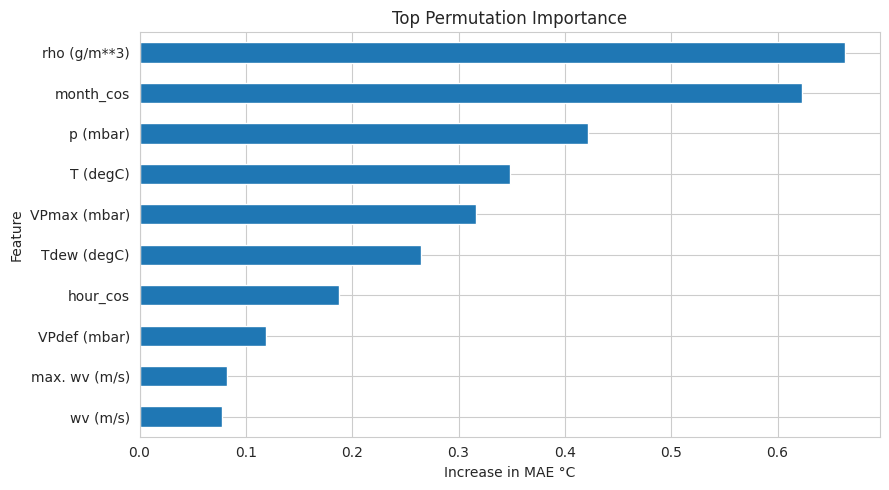

In [36]:
# Calculate permutation feature importance
baseline_mae = mean_absolute_error(test_target_raw, best_pred)
importance_rows, rng = [], np.random.default_rng(SEED)

for i, name in enumerate(feature_cols):
    X_perm = X_test.copy()
    shuffled = X_perm[:, :, i].copy().ravel()
    rng.shuffle(shuffled)
    X_perm[:, :, i] = shuffled.reshape(X_perm[:, :, i].shape)

    if best_model_name == "ANN": pred_s = ann_best.predict(X_perm, verbose=0).ravel()
    elif best_model_name == "LSTM": pred_s = lstm_best.predict(X_perm, verbose=0).ravel()
    elif best_model_name == "GRU variant": pred_s = variant_best.predict(X_perm, verbose=0).ravel()
    elif best_model_name == "Linear Regression (Ridge)": pred_s = ridge.predict(X_perm.reshape(len(X_perm), -1))
    else: pred_s = X_perm[:, -1, target_idx]

    pred_deg = target_scaler.inverse_transform(pred_s.reshape(-1, 1)).ravel()
    importance_rows.append({"Feature": name, "MAE increase": mean_absolute_error(test_target_raw, pred_deg) - baseline_mae})

importance_df = pd.DataFrame(importance_rows).sort_values("MAE increase", ascending=False)
display(importance_df.head(10))

# Plot top features
importance_df.head(10).sort_values("MAE increase").plot.barh(x="Feature", y="MAE increase", figsize=(9, 5), legend=False)
plt.title("Top Permutation Importance"); plt.xlabel("Increase in MAE °C")
plt.tight_layout(); plt.show()

### Findings:

- **Feature importance:** `rho (g/m³)` is the most influential feature, followed by `month_cos` and `p (mbar)`, indicating that humidity, seasonal patterns, and atmospheric pressure strongly affect predictions.
- **Top features:** `rho` (~0.66°C), `month_cos` (~0.62°C), and `p` (~0.42°C) show the largest increase in MAE when shuffled, suggesting the model relies heavily on them.
- **Moderate influence:** `T (degC)`, `VPMAX (mbar)`, and `Tdew (degC)` also contribute significantly, while `hour_cos` has a moderate impact.
- **Least important features:** `VPdef`, `max. wv`, and `wv` have relatively low permutation importance, indicating a smaller contribution to the model's predictive performance.

**Conclusion:** The model relies primarily on humidity, seasonal information, atmospheric pressure, and temperature-related features for accurate forecasting.

## Part 8 — Report & Conclusion (10 marks)

**Q8.1 (5 marks) – Executive summary** (150–200 words) for your manager: the problem, the best model, its error in °C, and whether the complexity of an LSTM is worth it.

**Q8.2 (3 marks) – Limitations & next steps** (at least 3 each): e.g., only one location, no weather-forecast inputs, trend drift across years, uncertainty estimates, etc.

**Q8.3 (2 marks) – Reproducibility.** Save your best model, the scaler (`joblib.dump`), and list the versions of the libraries you used. Restart the kernel and **Run All** — the notebook must run top to bottom without error.

## Executive Summary

This capstone investigates whether the past five days (120 hours) of hourly weather observations can predict temperature 24 hours ahead and evaluates whether recurrent neural networks outperform simpler models. Using the Jena Climate dataset (2009–2016), the data were cleaned, resampled to hourly frequency, and enhanced with cyclical time features. Persistence and Ridge Regression were used as baseline models, while ANN, LSTM, and GRU architectures were trained and evaluated on the same chronological test set using MAE, RMSE, and R². The GRU achieved the best performance, with a test MAE of approximately 2.20°C, RMSE of 2.79°C, and R² of 0.87, outperforming persistence (2.48°C) and Ridge Regression (2.32°C). The LSTM also outperformed the ANN but required greater training time. Overall, recurrent models offer improved forecasting accuracy, although their additional computational cost should be justified by the performance gains. Prediction errors were generally higher during winter months and sudden weather changes, highlighting the limitations of using historical observations alone.

## Limitations

1. The dataset represents a single location (Jena), limiting generalization across different climates and geographical regions.
2. The models rely solely on historical local observations without external weather forecasts, satellite data, or neighboring-station information.
3. Evaluation uses a single chronological train-test split, which may not fully capture seasonal variations or long-term climate drift.
4. Hyperparameter tuning was limited, and recurrent models showed signs of overfitting after a few epochs. Model rankings may also vary with different random seeds.
5. The models produce point forecasts without uncertainty estimates, limiting their ability to quantify prediction confidence.

## Next Steps

1. Incorporate external weather forecasts, neighboring-station observations, and additional meteorological features to improve prediction accuracy.
2. Systematically tune window length, network depth, hidden units, and regularization using tools such as KerasTuner.
3. Explore multi-step forecasting, Conv1D-LSTM, and Transformer-based architectures.
4. Introduce prediction intervals using quantile regression, MC Dropout, or ensemble methods.
5. Apply rolling time-series cross-validation and periodic monitoring to evaluate model robustness and detect performance drift.

In [37]:
# Select and save the best model and scalers
import joblib
ann_val_best, lstm_val_best, gru_val_best = [min(h.history["val_loss"]) for h in [ann_history, lstm_history, variant_history]]

final_model, final_model_name = (ann_best, "ANN") if ann_val_best <= min(lstm_val_best, gru_val_best) else (lstm_best, "LSTM") if lstm_val_best <= gru_val_best else (variant_best, "GRU")

final_model.save("best_weather_model.keras")
joblib.dump(feature_scaler, "feature_scaler.joblib")
joblib.dump(target_scaler, "target_scaler.joblib")
print("Saved:", final_model_name, "and both scalers.")

Saved: GRU and both scalers.


---
### Completed By - **Monish D.Y. - 230701195**